In [1]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
import os

from google.colab import files
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.ensemble import (
    RandomForestRegressor,
    ExtraTreesRegressor,
    GradientBoostingRegressor
)
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

print("Libraries imported successfully!")


Libraries imported successfully!


In [ ]:

import zipfile
import pandas as pd
from google.colab import files
from IPython.display import display

# Upload your ZIP file
uploaded = files.upload()

zip_name = next(iter(uploaded))

# Read CSV files inside ZIP
with zipfile.ZipFile(zip_name, "r") as z:
    csv_files = [
        f for f in z.namelist()
        if f.lower().endswith(".csv") and not f.startswith("__MACOSX/")
    ]

print("CSV files found:")
for i, file in enumerate(csv_files, start=1):
    print(f"{i}. {file}")

# Select the dataset
print("\nEnter the dataset number you want to use:")
choice = int(input("Dataset number: "))

selected_file = csv_files[choice - 1]

with zipfile.ZipFile(zip_name, "r") as z:
    with z.open(selected_file) as f:
        df = pd.read_csv(f)

print("\nSelected dataset:", selected_file)
print("Dataset shape:", df.shape)
print("\nColumn names:")
print(df.columns.tolist())

display(df.head())


In [ ]:

# Standardize column names
df.columns = (
    df.columns.str.strip()
    .str.lower()
    .str.replace(r"[^a-z0-9]+", "_", regex=True)
    .str.strip("_")
)

# Map common dataset column names
aliases = {
    "price": "selling_price",
    "sellingprice": "selling_price",
    "kms_driven": "km_driven",
    "kilometers_driven": "km_driven",
    "fuel_type": "fuel",
    "car": "name"
}

df = df.rename(columns=aliases)

# Required columns
required = [
    "year", "km_driven", "fuel",
    "seller_type", "transmission", "owner",
    "selling_price"
]

missing = [c for c in required if c not in df.columns]

if missing:
    raise ValueError(
        f"Missing columns: {missing}. "
        f"Available columns: {df.columns.tolist()}"
    )

# Select available features
features = [
    c for c in [
        "name", "year", "km_driven", "fuel",
        "seller_type", "transmission", "owner"
    ]
    if c in df.columns
]

data = df[features + ["selling_price"]].copy()

# Convert numerical columns
for col in ["year", "km_driven", "selling_price"]:
    data[col] = pd.to_numeric(data[col], errors="coerce")

# Clean categorical columns
categorical_cols = [
    c for c in features if c not in ["year", "km_driven"]
]

for col in categorical_cols:
    data[col] = data[col].astype("string").str.strip()
    data[col] = data[col].replace("", pd.NA)

# Remove invalid target values
data = data.dropna(subset=["selling_price"])
data = data[data["selling_price"] > 0]
data = data[
    data["km_driven"].isna() | (data["km_driven"] >= 0)
]
data = data.drop_duplicates().reset_index(drop=True)

if len(data) < 20:
    raise ValueError("Please upload a larger valid dataset.")

print("Cleaned dataset shape:", data.shape)
display(data.head())

print("\nMissing values:")
display(data.isnull().sum().to_frame("Missing Values"))


Cleaned dataset shape: (6925, 8)


,name,year,km_driven,fuel,seller_type,transmission,owner,selling_price
0,Maruti Swift Dzire VDI,2014,145500,Diesel,Individual,Manual,First Owner,450000
1,Skoda Rapid 1.5 TDI Ambition,2014,120000,Diesel,Individual,Manual,Second Owner,370000
2,Honda City 2017-2020 EXi,2006,140000,Petrol,Individual,Manual,Third Owner,158000
3,Hyundai i20 Sportz Diesel,2010,127000,Diesel,Individual,Manual,First Owner,225000
4,Maruti Swift VXI BSIII,2007,120000,Petrol,Individual,Manual,First Owner,130000



Missing values:


,Missing Values
name,0
year,0
km_driven,0
fuel,0
seller_type,0
transmission,0
owner,0
selling_price,0


,name,year,km_driven,fuel,seller_type,transmission,owner,selling_price
count,6925,6925.000000,6.925000e+03,6925,6925,6925,6925,6.925000e+03
unique,2058,NaN,NaN,4,3,2,5,NaN
top,Maruti Swift Dzire VDI,NaN,NaN,Diesel,Individual,Manual,First Owner,NaN
freq,118,NaN,NaN,3754,6218,6341,4241,NaN
mean,NaN,2013.419783,7.400041e+04,NaN,NaN,NaN,NaN,5.172603e+05
std,NaN,4.078354,5.836098e+04,NaN,NaN,NaN,NaN,5.198038e+05
min,NaN,1983.000000,1.000000e+00,NaN,NaN,NaN,NaN,2.999900e+04
25%,NaN,2011.000000,4.000000e+04,NaN,NaN,NaN,NaN,2.500000e+05
50%,NaN,2014.000000,7.000000e+04,NaN,NaN,NaN,NaN,4.000000e+05
75%,NaN,2017.000000,1.000000e+05,NaN,NaN,NaN,NaN,6.340000e+05


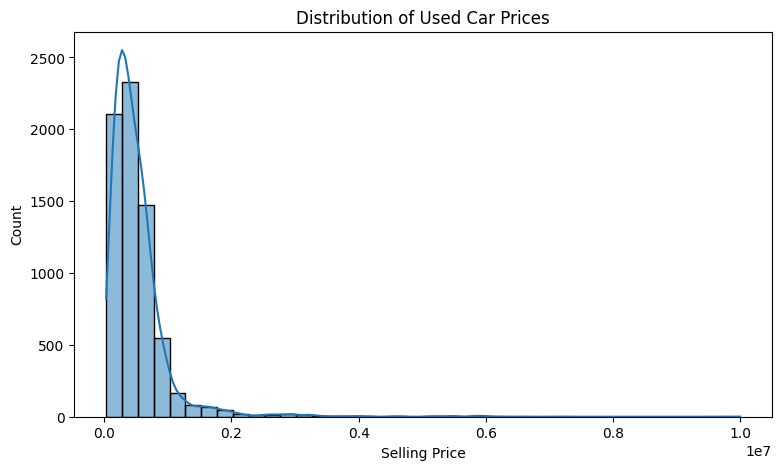

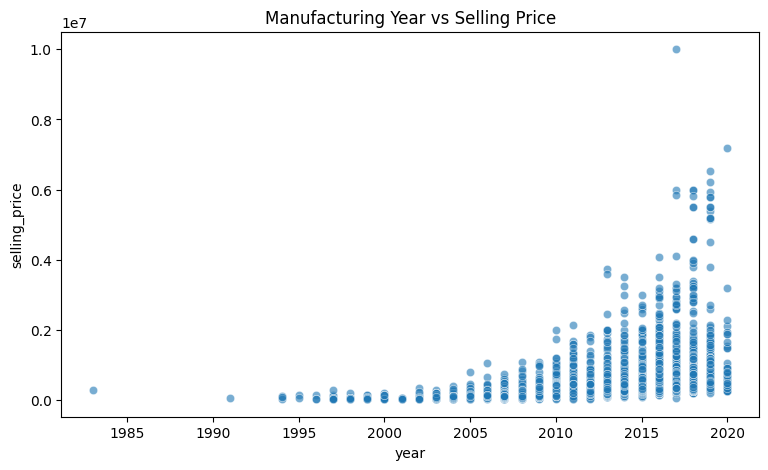

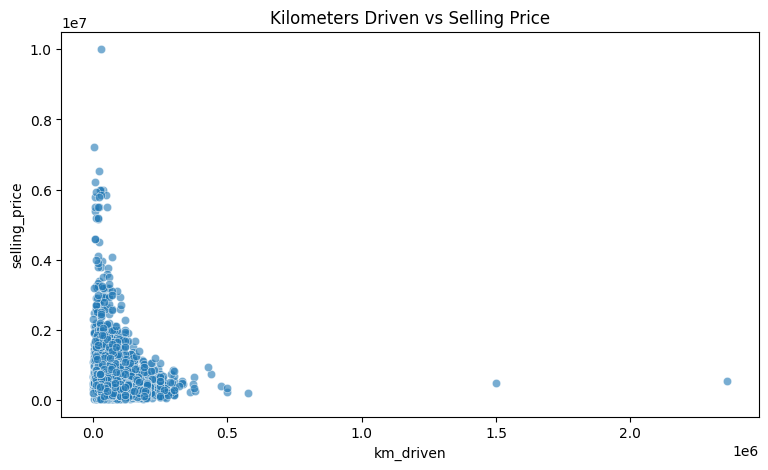

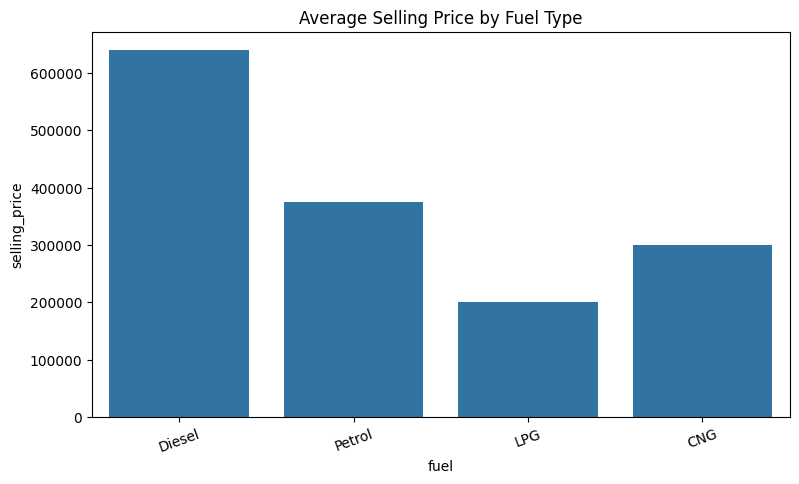

In [ ]:

# Statistical summary
display(data.describe(include="all"))

# Price distribution
plt.figure(figsize=(9, 5))
sns.histplot(data=data, x="selling_price", bins=40, kde=True)
plt.title("Distribution of Used Car Prices")
plt.xlabel("Selling Price")
plt.show()

# Manufacturing year vs price
plt.figure(figsize=(9, 5))
sns.scatterplot(
    data=data, x="year", y="selling_price", alpha=0.6
)
plt.title("Manufacturing Year vs Selling Price")
plt.show()

# Kilometers driven vs price
plt.figure(figsize=(9, 5))
sns.scatterplot(
    data=data, x="km_driven", y="selling_price", alpha=0.6
)
plt.title("Kilometers Driven vs Selling Price")
plt.show()

# Average price by fuel type
plt.figure(figsize=(9, 5))
sns.barplot(
    data=data, x="fuel", y="selling_price", errorbar=None
)
plt.title("Average Selling Price by Fuel Type")
plt.xticks(rotation=20)
plt.show()


In [ ]:

X = data[features]
y = data["selling_price"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42
)

numeric_features = ["year", "km_driven"]
categorical_features = [
    c for c in features if c not in numeric_features
]

numeric_transformer = Pipeline([
    ("imputer", SimpleImputer(strategy="median"))
])

categorical_transformer = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer([
    ("numeric", numeric_transformer, numeric_features),
    ("categorical", categorical_transformer, categorical_features)
])

models = {
    "Random Forest": RandomForestRegressor(
        n_estimators=200,
        min_samples_leaf=2,
        random_state=42,
        n_jobs=-1
    ),
    "Extra Trees": ExtraTreesRegressor(
        n_estimators=200,
        min_samples_leaf=2,
        random_state=42,
        n_jobs=-1
    ),
    "Gradient Boosting": GradientBoostingRegressor(
        n_estimators=150,
        learning_rate=0.05,
        max_depth=3,
        loss="huber",
        random_state=42
    )
}

trained_models = {}
results = []

for name, regressor in models.items():
    print(f"Training {name}...")

    pipeline = Pipeline([
        ("preprocessor", preprocessor),
        ("model", regressor)
    ])

    pipeline.fit(X_train, y_train)
    predictions = pipeline.predict(X_test)

    mae = mean_absolute_error(y_test, predictions)
    rmse = np.sqrt(mean_squared_error(y_test, predictions))
    r2 = r2_score(y_test, predictions)

    trained_models[name] = pipeline

    results.append({
        "Model": name,
        "MAE": mae,
        "RMSE": rmse,
        "R2 Score": r2
    })

results_df = pd.DataFrame(results).sort_values("MAE")
display(results_df.round(3))


Training Random Forest...
Training Extra Trees...
Training Gradient Boosting...


,Model,MAE,RMSE,R2 Score
1,Extra Trees,140310.154,320201.439,0.580
0,Random Forest,148326.365,333982.396,0.544
2,Gradient Boosting,152369.817,351526.820,0.494


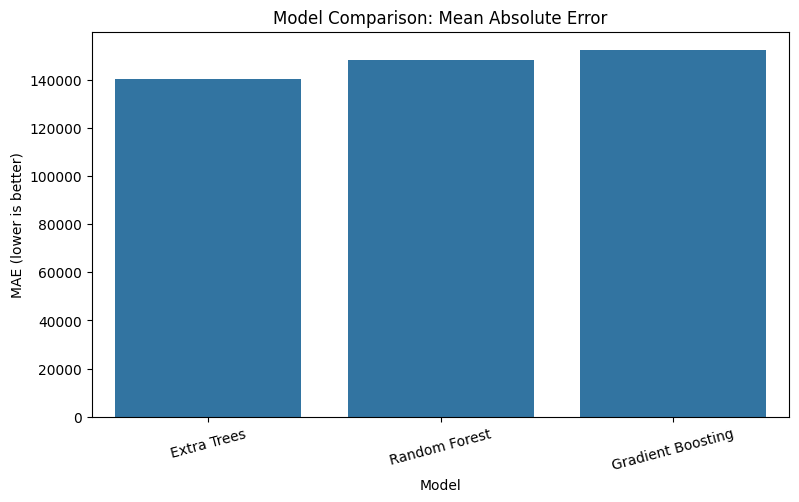

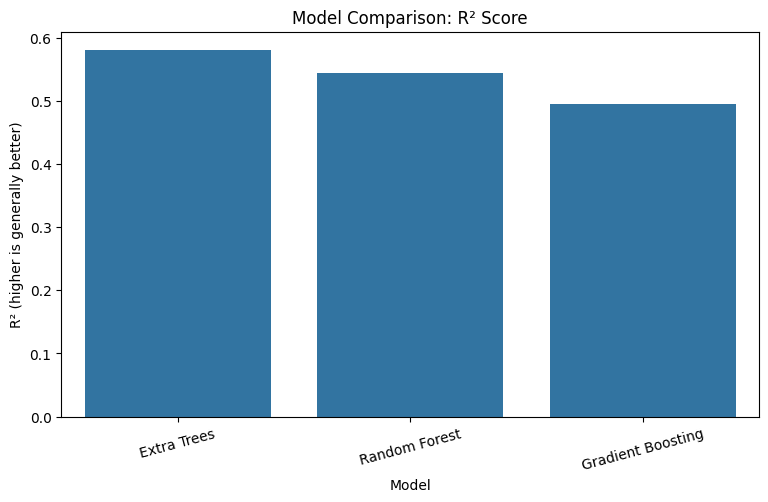

Selected model: Extra Trees


In [ ]:

plt.figure(figsize=(9, 5))
sns.barplot(data=results_df, x="Model", y="MAE")
plt.title("Model Comparison: Mean Absolute Error")
plt.ylabel("MAE (lower is better)")
plt.xticks(rotation=15)
plt.show()

plt.figure(figsize=(9, 5))
sns.barplot(data=results_df, x="Model", y="R2 Score")
plt.title("Model Comparison: R² Score")
plt.ylabel("R² (higher is generally better)")
plt.xticks(rotation=15)
plt.show()

best_name = results_df.iloc[0]["Model"]
best_model = trained_models[best_name]

print("Selected model:", best_name)


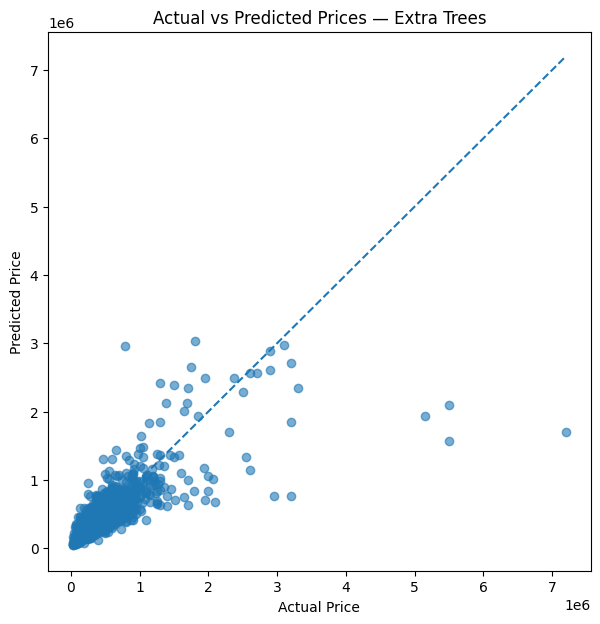

Mean Absolute Error: 140310.15
Root Mean Squared Error: 320201.44
R² Score: 0.5804


In [ ]:

y_pred = best_model.predict(X_test)

plt.figure(figsize=(7, 7))
plt.scatter(y_test, y_pred, alpha=0.6)

low = min(y_test.min(), y_pred.min())
high = max(y_test.max(), y_pred.max())

plt.plot([low, high], [low, high], linestyle="--")
plt.xlabel("Actual Price")
plt.ylabel("Predicted Price")
plt.title(f"Actual vs Predicted Prices — {best_name}")
plt.show()

print("Mean Absolute Error:", round(
    mean_absolute_error(y_test, y_pred), 2
))
print("Root Mean Squared Error:", round(
    np.sqrt(mean_squared_error(y_test, y_pred)), 2
))
print("R² Score:", round(r2_score(y_test, y_pred), 4))


In [ ]:

def choose_value(column, default):
    values = data[column].dropna().astype(str).unique().tolist()
    return default if default in values else (
        values[0] if values else default
    )

if "name" in features:
    car_name = choose_value("name", "Maruti Swift")
else:
    car_name = None

year = int(data["year"].median())
km_driven = int(data["km_driven"].median())

fuel = choose_value("fuel", "Petrol")
seller_type = choose_value("seller_type", "Individual")
transmission = choose_value("transmission", "Manual")
owner = choose_value("owner", "First Owner")

print("Example car prediction")
if "name" in features:
    print("Car:", car_name)
print("Year:", year)
print("Kilometers driven:", km_driven)
print("Fuel:", fuel)
print("Seller:", seller_type)
print("Transmission:", transmission)
print("Owner:", owner)

car = {
    "year": year,
    "km_driven": km_driven,
    "fuel": fuel,
    "seller_type": seller_type,
    "transmission": transmission,
    "owner": owner
}

if "name" in features:
    car["name"] = car_name

car_df = pd.DataFrame([{
    feature: car[feature] for feature in features
}])

predicted_price = best_model.predict(car_df)[0]

print(f"\nEstimated used car price: {predicted_price:,.2f}")
print("Price units match the dataset.")


Example car prediction
Car: Maruti Swift Dzire VDI
Year: 2014
Kilometers driven: 70000
Fuel: Petrol
Seller: Individual
Transmission: Manual
Owner: First Owner

Estimated used car price: 318,078.35
Price units match the dataset.
